In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

BASE_DIR = "/content/drive/MyDrive/Mendeley_16Class_Dataset"
TRAIN_DIR = os.path.join(BASE_DIR, "train")
TEST_DIR  = os.path.join(BASE_DIR, "test")

os.makedirs(TRAIN_DIR, exist_ok=True)
os.makedirs(TEST_DIR, exist_ok=True)

print("Created:", BASE_DIR)


Created: /content/drive/MyDrive/Mendeley_16Class_Dataset


In [ ]:
!unzip "/content/drive/MyDrive/Original Image (1).zip" -d /content/mendeley_raw


Archive:  /content/drive/MyDrive/Original Image (1).zip
   creating: /content/mendeley_raw/Original Image/FreshApple/
  inflating: /content/mendeley_raw/Original Image/FreshApple/FreshApple (1).jpg  
  inflating: /content/mendeley_raw/Original Image/FreshApple/FreshApple (10).jpg  
  inflating: /content/mendeley_raw/Original Image/FreshApple/FreshApple (100).jpg  
  inflating: /content/mendeley_raw/Original Image/FreshApple/FreshApple (101).jpg  
  inflating: /content/mendeley_raw/Original Image/FreshApple/FreshApple (102).jpg  
  inflating: /content/mendeley_raw/Original Image/FreshApple/FreshApple (103).jpg  
  inflating: /content/mendeley_raw/Original Image/FreshApple/FreshApple (104).jpg  
  inflating: /content/mendeley_raw/Original Image/FreshApple/FreshApple (105).jpg  
  inflating: /content/mendeley_raw/Original Image/FreshApple/FreshApple (106).jpg  
  inflating: /content/mendeley_raw/Original Image/FreshApple/FreshApple (107).jpg  
  inflating: /content/mendeley_raw/Original I

In [ ]:
!ls "/content/mendeley_raw/Original Image"


FreshApple   FreshJujube       RottenApple   RottenJujube
FreshBanana  FreshOrange       RottenBanana  RottenOrange
FreshGrape   FreshPomegranate  RottenGrape   RottenPomegranate
FreshGuava   FreshStrawberry   RottenGuava   RottenStrawberry


In [ ]:
import os, shutil, random

SOURCE_DIR = "/content/mendeley_raw/Original Image"
BASE_DIR   = "/content/drive/MyDrive/Mendeley_16Class_Dataset"
TRAIN_DIR  = os.path.join(BASE_DIR, "train")
TEST_DIR   = os.path.join(BASE_DIR, "test")

os.makedirs(TRAIN_DIR, exist_ok=True)
os.makedirs(TEST_DIR, exist_ok=True)

SPLIT_RATIO = 0.8

for class_name in os.listdir(SOURCE_DIR):
    class_path = os.path.join(SOURCE_DIR, class_name)
    if not os.path.isdir(class_path):
        continue

    images = os.listdir(class_path)
    random.shuffle(images)

    split_idx = int(len(images) * SPLIT_RATIO)
    train_imgs = images[:split_idx]
    test_imgs  = images[split_idx:]

    os.makedirs(os.path.join(TRAIN_DIR, class_name), exist_ok=True)
    os.makedirs(os.path.join(TEST_DIR, class_name), exist_ok=True)

    for img in train_imgs:
        shutil.copy(
            os.path.join(class_path, img),
            os.path.join(TRAIN_DIR, class_name, img)
        )

    for img in test_imgs:
        shutil.copy(
            os.path.join(class_path, img),
            os.path.join(TEST_DIR, class_name, img)
        )

    print(f"{class_name}: {len(train_imgs)} train / {len(test_imgs)} test")


FreshStrawberry: 160 train / 40 test
RottenPomegranate: 160 train / 40 test
RottenApple: 160 train / 40 test
FreshApple: 160 train / 40 test
FreshBanana: 160 train / 40 test
RottenGrape: 160 train / 40 test
FreshPomegranate: 160 train / 40 test
RottenBanana: 160 train / 40 test
RottenGuava: 160 train / 40 test
FreshGrape: 160 train / 40 test
RottenOrange: 160 train / 40 test
FreshOrange: 160 train / 40 test
RottenStrawberry: 160 train / 40 test
FreshGuava: 160 train / 40 test
RottenJujube: 160 train / 40 test
FreshJujube: 160 train / 40 test


In [ ]:
!ls /content/drive/MyDrive/Mendeley_16Class_Dataset/train


FreshApple   FreshJujube       RottenApple   RottenJujube
FreshBanana  FreshOrange       RottenBanana  RottenOrange
FreshGrape   FreshPomegranate  RottenGrape   RottenPomegranate
FreshGuava   FreshStrawberry   RottenGuava   RottenStrawberry


In [ ]:
!ls /content/drive/MyDrive/Mendeley_16Class_Dataset/test


FreshApple   FreshJujube       RottenApple   RottenJujube
FreshBanana  FreshOrange       RottenBanana  RottenOrange
FreshGrape   FreshPomegranate  RottenGrape   RottenPomegranate
FreshGuava   FreshStrawberry   RottenGuava   RottenStrawberry


In [ ]:
import os
import tensorflow as tf
import numpy as np

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, CSVLogger


In [ ]:
DATASET_DIR = "/content/drive/MyDrive/Mendeley_16Class_Dataset"
TRAIN_DIR = os.path.join(DATASET_DIR, "train")
TEST_DIR  = os.path.join(DATASET_DIR, "test")

SAVE_DIR = "/content/drive/MyDrive/MobileNetV2_16Class_Final"
os.makedirs(SAVE_DIR, exist_ok=True)

print("Train:", TRAIN_DIR)
print("Test :", TEST_DIR)


Train: /content/drive/MyDrive/Mendeley_16Class_Dataset/train
Test : /content/drive/MyDrive/Mendeley_16Class_Dataset/test


In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(rescale=1./255)
test_datagen  = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True
)

val_gen = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

NUM_CLASSES = train_gen.num_classes
CLASS_NAMES = list(train_gen.class_indices.keys())

print("Number of classes:", NUM_CLASSES)
print("Classes:", CLASS_NAMES)


Found 2560 images belonging to 16 classes.
Found 640 images belonging to 16 classes.
Number of classes: 16
Classes: ['FreshApple', 'FreshBanana', 'FreshGrape', 'FreshGuava', 'FreshJujube', 'FreshOrange', 'FreshPomegranate', 'FreshStrawberry', 'RottenApple', 'RottenBanana', 'RottenGrape', 'RottenGuava', 'RottenJujube', 'RottenOrange', 'RottenPomegranate', 'RottenStrawberry']


In [ ]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze backbone
for layer in base_model.layers:
    layer.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation="relu")(x)
x = Dropout(0.5)(x)
output = Dense(NUM_CLASSES, activation="softmax")(x)

model = Model(inputs=base_model.input, outputs=output)

model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,590,032 (9.88 MB)

 Trainable params: 332,048 (1.27 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
checkpoint_cb = ModelCheckpoint(
    filepath=os.path.join(SAVE_DIR, "mobilenetv2_16class_best.keras"),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

earlystop_cb = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

csv_logger = CSVLogger(
    os.path.join(SAVE_DIR, "training_log.csv"),
    append=False
)


In [ ]:
EPOCHS = 30

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS,
    callbacks=[checkpoint_cb, earlystop_cb, csv_logger]
)


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.1814 - loss: 2.7779
Epoch 1: val_loss improved from inf to 1.23041, saving model to /content/drive/MyDrive/MobileNetV2_16Class_Final/mobilenetv2_16class_best.keras
80/80 ━━━━━━━━━━━━━━━━━━━━ 298s 4s/step - accuracy: 0.1831 - loss: 2.7712 - val_accuracy: 0.7750 - val_loss: 1.2304
Epoch 2/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6568 - loss: 1.2525
Epoch 2: val_loss improved from 1.23041 to 0.66371, saving model to /content/drive/MyDrive/MobileNetV2_16Class_Final/mobilenetv2_16class_best.keras
80/80 ━━━━━━━━━━━━━━━━━━━━ 256s 3s/step - accuracy: 0.6571 - loss: 1.2510 - val_accuracy: 0.8922 - val_loss: 0.6637
Epoch 3/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7841 - loss: 0.7965
Epoch 3: val_loss improved from 0.66371 to 0.43550, saving model to /content/drive/MyDrive/MobileNetV2_16Class_Final/mobilenetv2_16class_best.keras
80/80 ━━━━━━━━━━━━━━━━━━━━ 251s 3s/step - accuracy: 0.7843 - loss: 0.7959 - val

In [ ]:
model.save(
    os.path.join(SAVE_DIR, "mobilenetv2_16class_final.keras")
)

print("Final 16-class MobileNetV2 model saved.")


Final 16-class MobileNetV2 model saved.


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.models import load_model
from sklearn.metrics import confusion_matrix, classification_report


In [ ]:
MODEL_PATH = "/content/drive/MyDrive/MobileNetV2_16Class_Final/mobilenetv2_16class_best.keras"
model = load_model(MODEL_PATH)

print("Model loaded successfully.")


Model loaded successfully.


In [ ]:
# Ensure generator is NOT shuffled
val_gen.reset()

y_true = val_gen.classes
y_prob = model.predict(val_gen, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

class_names = list(val_gen.class_indices.keys())


20/20 ━━━━━━━━━━━━━━━━━━━━ 81s 4s/step


In [ ]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )
)


                   precision    recall  f1-score   support

       FreshApple     1.0000    1.0000    1.0000        40
      FreshBanana     1.0000    1.0000    1.0000        40
       FreshGrape     0.9286    0.9750    0.9512        40
       FreshGuava     1.0000    1.0000    1.0000        40
      FreshJujube     0.9756    1.0000    0.9877        40
      FreshOrange     1.0000    0.9750    0.9873        40
 FreshPomegranate     0.9512    0.9750    0.9630        40
  FreshStrawberry     1.0000    1.0000    1.0000        40
      RottenApple     0.9750    0.9750    0.9750        40
     RottenBanana     0.9750    0.9750    0.9750        40
      RottenGrape     1.0000    0.9250    0.9610        40
      RottenGuava     0.9750    0.9750    0.9750        40
     RottenJujube     0.9756    1.0000    0.9877        40
     RottenOrange     0.9744    0.9500    0.9620        40
RottenPomegranate     0.9487    0.9250    0.9367        40
 RottenStrawberry     0.9756    1.0000    0.9877       

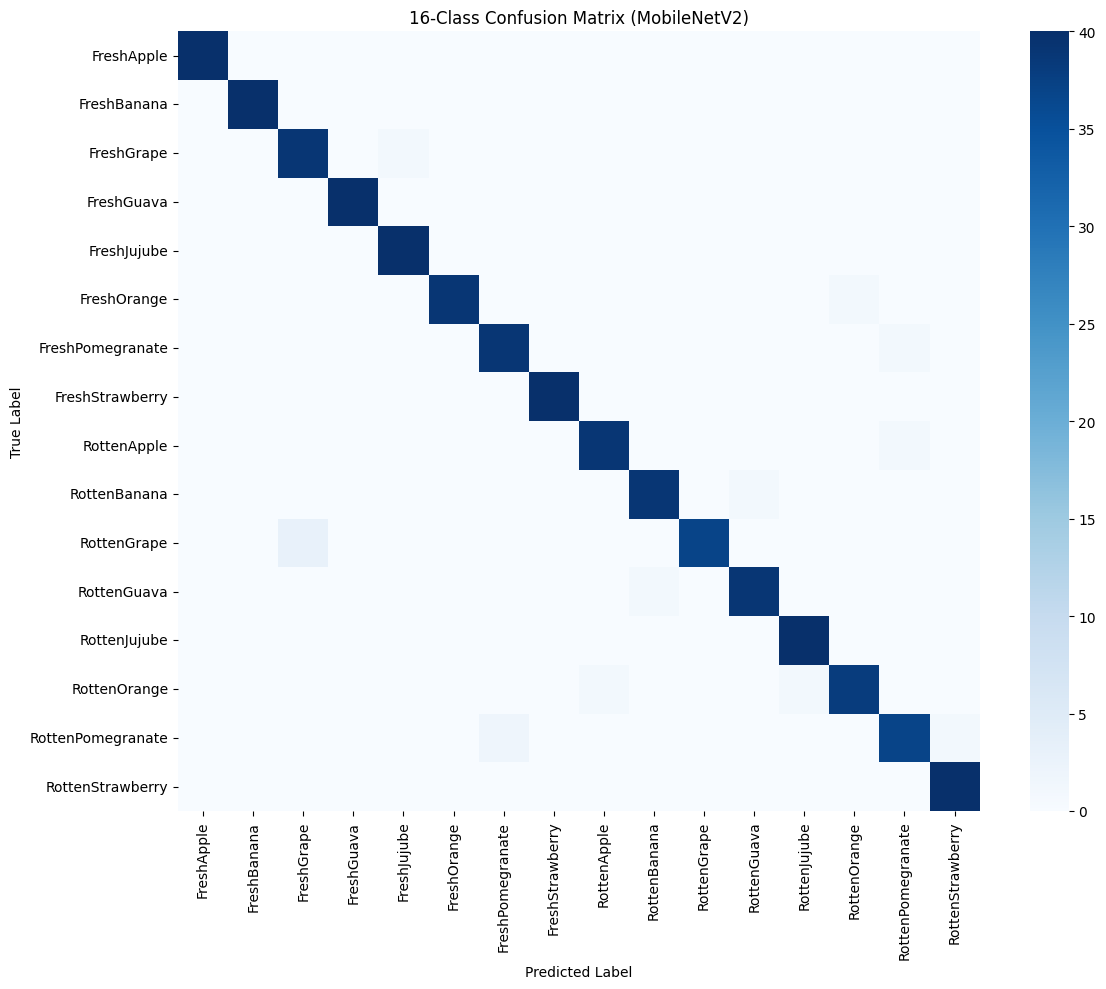

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    xticklabels=class_names,
    yticklabels=class_names,
    cmap="Blues",
    fmt="d"
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("16-Class Confusion Matrix (MobileNetV2)")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:
CONF_THRESHOLD = 0.60   # conservative, can mention sensitivity analysis


In [ ]:
from tensorflow.keras.preprocessing import image

def predict_with_unknown(img_path, model, class_names, threshold=0.6):
    img = image.load_img(img_path, target_size=(224, 224))
    img_arr = image.img_to_array(img) / 255.0
    img_arr = np.expand_dims(img_arr, axis=0)

    probs = model.predict(img_arr)[0]
    max_prob = np.max(probs)
    pred_idx = np.argmax(probs)

    if max_prob < threshold:
        return "Unknown", max_prob
    else:
        return class_names[pred_idx], max_prob


In [ ]:
test_images = [
    "/content/drive/MyDrive/aiapple.jpg",      # fruit
    "/content/drive/MyDrive/aibanana.webp",    # fruit
    "/content/drive/MyDrive/rakshit_check.png" # non-fruit
]

for img_path in test_images:
    label, conf = predict_with_unknown(
        img_path,
        model,
        class_names,
        threshold=CONF_THRESHOLD
    )
    print(f"{os.path.basename(img_path)} → {label} (confidence={conf:.3f})")


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
aiapple.jpg → Unknown (confidence=0.347)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
aibanana.webp → RottenGrape (confidence=0.827)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
rakshit_check.png → RottenStrawberry (confidence=0.723)


In [ ]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score


In [ ]:
from tensorflow.keras.models import load_model

model = load_model(
    "/content/drive/MyDrive/MobileNetV2_16Class_Final/mobilenetv2_16class_best.keras"
)


In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json


In [ ]:
!kaggle datasets download -d sriramr/fruits-fresh-and-rotten-for-classification


Dataset URL: https://www.kaggle.com/datasets/sriramr/fruits-fresh-and-rotten-for-classification
License(s): unknown
100% 3.57G/3.58G [00:46<00:00, 50.9MB/s]
100% 3.58G/3.58G [00:46<00:00, 82.2MB/s]


In [ ]:
!unzip fruits-fresh-and-rotten-for-classification.zip -d /content/kaggle_fruits


Streaming output truncated to the last 5000 lines.
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.02.09 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.02.18 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.02.24 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.02.37 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.02.51 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.03.02 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.03.12 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.03.2

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

test_dir = "/content/kaggle_fruits/dataset/test"

test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode=None,   # IMPORTANT
    shuffle=False
)


Found 2698 images belonging to 6 classes.


In [ ]:
import numpy as np

true_fruit_labels = []

for path in test_generator.filepaths:
    folder = path.split("/")[-2].lower()

    if "apple" in folder:
        true_fruit_labels.append("Apple")
    elif "banana" in folder:
        true_fruit_labels.append("Banana")
    elif "orange" in folder:
        true_fruit_labels.append("Orange")
    else:
        true_fruit_labels.append("Unknown")

true_fruit_labels = np.array(true_fruit_labels)

print("Sample true labels:", true_fruit_labels[:10])


Sample true labels: ['Apple' 'Apple' 'Apple' 'Apple' 'Apple' 'Apple' 'Apple' 'Apple' 'Apple'
 'Apple']


In [ ]:
# Predict probabilities for all test images
y_prob = model.predict(test_generator, verbose=1)

# Take argmax → 16-class index
y_pred_idx = np.argmax(y_prob, axis=1)

print("Pred indices sample:", y_pred_idx[:10])


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


85/85 ━━━━━━━━━━━━━━━━━━━━ 132s 1s/step
Pred indices sample: [4 4 0 8 4 4 0 0 4 0]


In [ ]:
model_classes = [
    "FreshApple","FreshBanana","FreshGrape","FreshGuava",
    "FreshJujube","FreshOrange","FreshPomegranate","FreshStrawberry",
    "RottenApple","RottenBanana","RottenGrape","RottenGuava",
    "RottenJujube","RottenOrange","RottenPomegranate","RottenStrawberry"
]

predicted_16class = np.array([model_classes[i] for i in y_pred_idx])

print("Sample 16-class predictions:", predicted_16class[:10])


Sample 16-class predictions: ['FreshJujube' 'FreshJujube' 'FreshApple' 'RottenApple' 'FreshJujube'
 'FreshJujube' 'FreshApple' 'FreshApple' 'FreshJujube' 'FreshApple']


In [ ]:
def extract_fruit(pred_label):
    if "Apple" in pred_label:
        return "Apple"
    elif "Banana" in pred_label:
        return "Banana"
    elif "Orange" in pred_label:
        return "Orange"
    else:
        return "Other"

predicted_fruit = np.array([extract_fruit(p) for p in predicted_16class])

print("Sample predicted fruits:", predicted_fruit[:10])


Sample predicted fruits: ['Other' 'Other' 'Apple' 'Apple' 'Other' 'Other' 'Apple' 'Apple' 'Other'
 'Apple']


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

print(
    classification_report(
        true_fruit_labels,
        predicted_fruit,
        labels=["Apple","Banana","Orange"],
        digits=4
    )
)


              precision    recall  f1-score   support

       Apple     0.8577    0.4116    0.5563       996
      Banana     0.9487    0.9550    0.9519       911
      Orange     0.8298    0.6903    0.7536       791

   micro avg     0.8894    0.6768    0.7687      2698
   macro avg     0.8788    0.6856    0.7539      2698
weighted avg     0.8803    0.6768    0.7477      2698



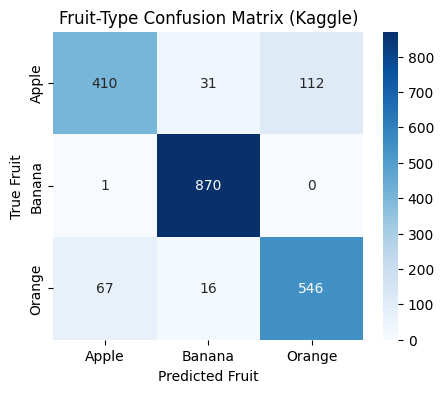

In [ ]:
cm = confusion_matrix(
    true_fruit_labels,
    predicted_fruit,
    labels=["Apple","Banana","Orange"]
)

plt.figure(figsize=(5,4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Apple","Banana","Orange"],
    yticklabels=["Apple","Banana","Orange"],
    cmap="Blues"
)
plt.xlabel("Predicted Fruit")
plt.ylabel("True Fruit")
plt.title("Fruit-Type Confusion Matrix (Kaggle)")
plt.show()


In [ ]:
import pandas as pd

df = pd.DataFrame({
    "TrueFruit": true_fruit_labels,
    "Predicted16Class": predicted_16class
})

df.head(10)


,TrueFruit,Predicted16Class
0,Apple,FreshJujube
1,Apple,FreshJujube
2,Apple,FreshApple
3,Apple,RottenApple
4,Apple,FreshJujube
5,Apple,FreshJujube
6,Apple,FreshApple
7,Apple,FreshApple
8,Apple,FreshJujube
9,Apple,FreshApple


In [ ]:
pd.crosstab(df["TrueFruit"], df["Predicted16Class"])


Predicted16Class,FreshApple,FreshBanana,FreshGrape,FreshGuava,FreshJujube,FreshOrange,FreshPomegranate,FreshStrawberry,RottenApple,RottenBanana,RottenGrape,RottenGuava,RottenJujube,RottenOrange,RottenPomegranate,RottenStrawberry
TrueFruit,,,,,,,,,,,,,,,,
Apple,138,31,17,68,56,64,27,13,272,0,6,130,51,48,70,5
Banana,0,619,12,0,0,0,0,7,1,251,14,0,0,0,0,7
Orange,36,13,19,4,3,408,8,11,31,3,9,54,23,138,31,0
